# Build Your First Demand Forecast in Python

## How many bikes will cross the bridge next week?

![Six weeks of daily bike counts, then next week's forecast inside a shaded range](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/03-first-demand-forecast/figures/fig_title.png)

From raw data to a forecast you can act on, in 8 steps.

**Forecasting Made Easy, Episode 3** · Richel Attafuah, GStat

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RichelCode/Youtube/blob/main/forecasting-made-easy/03-first-demand-forecast/first_demand_forecast.ipynb)

# What you will learn today

1. What **demand forecasting** is, and why businesses care
2. The **8 steps** of a forecasting project, from question to answer
3. How to **clean** real data (and spot a broken sensor)
4. Why you **always start with a baseline**
5. How to **test fairly** on 26 different weeks
6. How to **learn from your worst days**
7. How to make a **real forecast with a range** you can plan around

# What is demand forecasting?

**Demand** = how much of something people will want or use.

| Who | Forecasts | So they can |
|---|---|---|
| A bakery | Loaves sold tomorrow | Bake enough, without waste |
| A power company | Electricity used tonight | Keep the lights on |
| A hospital | Patients next week | Plan staff and beds |
| A city | Bikes on a bridge next week | Plan repairs on the quiet days |

**Too low:** empty shelves, long queues. **Too high:** waste and cost.
**In plain words:** a market trader who brings more stock before Christmas is doing demand forecasting in her head.

# The 8 steps

![Eight steps: ask, load, look, clean, baseline, test fairly, learn from mistakes, forecast](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/03-first-demand-forecast/figures/fig_steps.png)

**Green:** get to know the data. **Orange:** build and test. **Purple:** the answer.

Most beginners jump straight to step 6. **The first five steps are where good forecasts are made.**

# Step 1: ask a clear question

| Question | Our answer |
|---|---|
| **What** are we forecasting? | Total bikes crossing Seattle's Fremont Bridge **per day** |
| **How far ahead?** | The **next 7 days** |
| **How often** will we forecast? | **Once a week** |
| **What decision** will it support? | For example: which days are quiet enough for path repairs |
| **How will we judge it?** | Average error in **bikes per day**, and how often the range holds the truth |

**In plain words:** "forecast bikes" is a wish. "Forecast total bikes for each of the next 7 days, every week" is a project.

In [1]:
import sys, os
if "google.colab" in sys.modules:   # on Colab: get the libraries and the data first
    get_ipython().run_line_magic("pip", 'install -q "chronos-forecasting>=2.3.2,<3" "statsforecast>=2.1,<3"')
    import urllib.request; os.makedirs("data", exist_ok=True)
    for f in ['data/fremont_bridge_daily.csv', 'data/seattle_weather_daily.csv']:
        if not os.path.exists(f): urllib.request.urlretrieve("https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/03-first-demand-forecast/" + f, f)

import os, time, warnings, logging
os.environ["TQDM_DISABLE"] = "1"; warnings.filterwarnings("ignore"); logging.disable(logging.WARNING)  # keep the screen clean
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch

H = 7          # forecast the next 7 days
SEASON = 7     # the weekly pattern repeats every 7 days
LEVEL = 80     # we also want an 80% range
WEEKS = 26     # test on 26 different weeks (half a year)

COLORS = {"SeasonalNaive": "#009E73", "AutoETS": "#D55E00", "Chronos2": "#0072B2"}
NAMES = {"SeasonalNaive": "Same day last week", "AutoETS": "AutoETS", "Chronos2": "Chronos-2 (AI)"}
plt.rcParams.update({"font.size": 15, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titlelocation": "left"})
np.random.seed(42); _ = torch.manual_seed(42)

import matplotlib.dates as mdates
def short_dates(ax):                      # dates like "5 Sep" on the x-axis
    ax.xaxis.set_major_locator(mdates.AutoDateLocator(maxticks=8))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%-d %b"))

# Step 2: load the data

- **Fremont Bridge bike counter**, City of Seattle (free, public domain). One row per day, January 2023 to September 2026
- Forecasting libraries expect three columns:

| Column | Meaning |
|---|---|
| `unique_id` | Which series this is (we only have one: `"fremont"`) |
| `ds` | The date |
| `y` | The number we want to forecast |

In [2]:
raw = pd.read_csv("data/fremont_bridge_daily.csv", parse_dates=["date"])
print(raw.head(3).to_string(index=False))
print(f"\n{len(raw):,} days, {raw.date.min():%d %b %Y} to {raw.date.max():%d %b %Y}")

      date  bikes  hours_counted
2023-01-01    902             24
2023-01-02   1186             24
2023-01-03   1957             24

1,369 days, 01 Jan 2023 to 30 Sep 2026


# Step 3: look at it

Always look before you model. We want to see:

- The **trend** (is it growing?) and the **yearly** rhythm (summer vs winter)
- The **weekly** rhythm up close (workdays vs weekends)
- Anything **strange**: gaps, spikes, sudden drops

*(Episode 2 is all about these three ingredients.)*

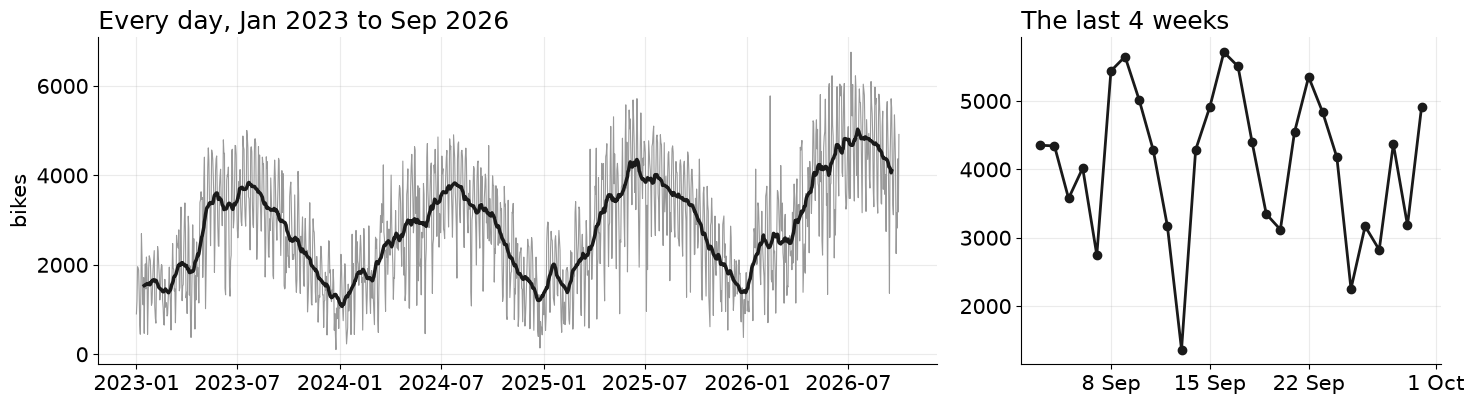

In [3]:
fig, axs = plt.subplots(1, 2, figsize=(15, 4.3), gridspec_kw={"width_ratios": [2, 1]})
axs[0].plot(raw.date, raw.bikes, color="#999", lw=.8)
axs[0].plot(raw.date, raw.bikes.rolling(28, center=True).mean(), color="#1A1A1A", lw=2.5)
axs[0].set(title="Every day, Jan 2023 to Sep 2026", ylabel="bikes")
last = raw.tail(28)
axs[1].plot(last.date, last.bikes, color="#1A1A1A", lw=2, marker="o")
axs[1].set(title="The last 4 weeks"); short_dates(axs[1])
plt.tight_layout(); plt.show()

# Step 4: clean it

Real data is never perfect. Three checks:

1. **Missing days?** Every date should be there, once
2. **Broken readings?** The column `hours_counted` should be 24 (23 is fine: the clocks change in March)
3. **Fix what is broken.** We replace a broken day with **the same weekday one week earlier**

**In plain words:** if a shop's till broke for half a day, that day's sales look terrible. But the customers did not disappear. Do not let a broken machine teach your model a false lesson.

In [4]:
all_days = pd.date_range(raw.date.min(), raw.date.max(), freq="D")
print("Missing days:", len(all_days) - raw.date.nunique(), "| Repeated days:", raw.date.duplicated().sum())

broken = raw["hours_counted"] < 23
print("Broken days:", raw.loc[broken, ["date", "bikes", "hours_counted"]].to_string(index=False))

df = raw.rename(columns={"date": "ds", "bikes": "y"}).assign(unique_id="fremont")
df["y"] = df["y"].astype(float).mask(broken)        # remove the broken reading
df["y"] = df["y"].fillna(df["y"].shift(7))           # same weekday, one week earlier
df = df[["unique_id", "ds", "y"]]
print("Fixed value for 18 Apr 2023:", int(df.loc[broken, "y"].iloc[0]), "bikes")

Missing days: 0 | Repeated days: 0
Broken days:       date  bikes  hours_counted
2023-04-18   1215             13
Fixed value for 18 Apr 2023: 2015 bikes


# Step 5: start with a baseline

A **baseline** is the simplest forecast you can make. Every real model must beat it.

- **Naive:** tomorrow = today. Bad idea here: it would forecast Monday from Sunday
- **Seasonal naive:** **this Monday = last Monday**. Same day, one week ago. This one copies the weekly rhythm for free

**In plain words:** if a fancy model cannot beat "same day last week", you do not need the fancy model.

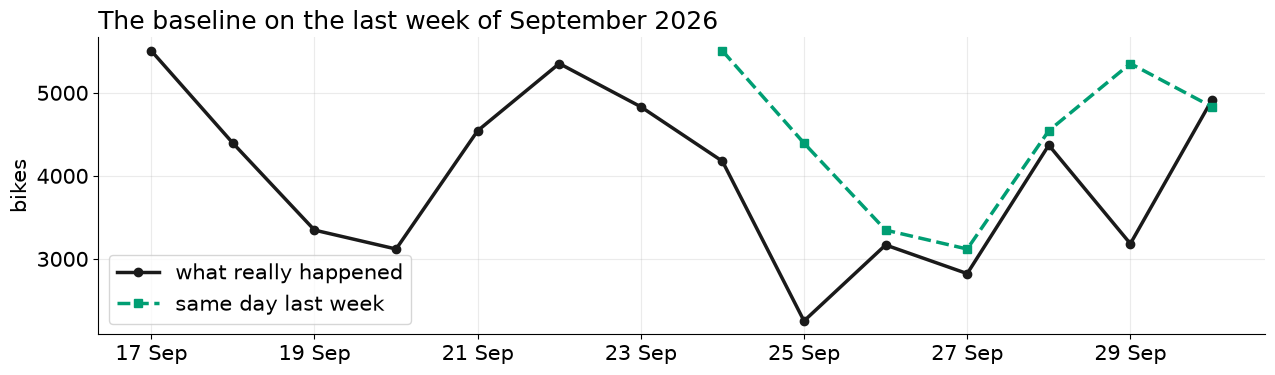

Average miss in the last 7 days: 911 bikes a day


In [5]:
recent = df.tail(14)
lazy = recent["y"].shift(7)              # same day last week
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(recent.ds, recent.y, color="#1A1A1A", lw=2.5, marker="o", label="what really happened")
ax.plot(recent.ds, lazy, color=COLORS["SeasonalNaive"], lw=2.5, ls="--", marker="s", label="same day last week")
ax.set(title="The baseline on the last week of September 2026", ylabel="bikes"); short_dates(ax)
ax.legend(loc="lower left"); plt.tight_layout(); plt.show()
print(f"Average miss in the last 7 days: {(recent.y - lazy).abs().mean():,.0f} bikes a day")

# Step 6: test fairly, on 26 weeks

![Rolling weekly windows: history the model may see, then the next 7 days](https://raw.githubusercontent.com/RichelCode/Youtube/main/forecasting-made-easy/03-first-demand-forecast/figures/fig_backtest.png)

**Pretend it is a past Wednesday. Use only the data before it, forecast the next 7 days, then check. Slide forward a week. Repeat 26 times.**

- This is called **backtesting**. It covers April to September 2026: spring, summer, rain and holidays
- **In plain words:** one good week can be luck. 26 good weeks is a skill

# The contestants

| Contestant | What it does |
|---|---|
| **Same day last week** (seasonal naive) | The baseline |
| **AutoETS** | A classic statistics model built from **E**rror, **T**rend and **S**easonality. Picks its own settings |
| **Chronos-2** | Amazon's AI forecasting model, used **zero-shot** (never trained on this data). All our test weeks are in 2026, after it was released |

First the two classic ones. In the code, `cross_validation` is the library's name for backtesting.

In [6]:
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive, AutoETS

t0 = time.time()
race = StatsForecast(
    models=[SeasonalNaive(season_length=SEASON), AutoETS(season_length=SEASON)], freq="D"
).cross_validation(df=df, h=H, step_size=H, n_windows=WEEKS, level=[LEVEL])
print(f"Baseline + AutoETS tested on {WEEKS} weeks in {time.time() - t0:.0f}s")
print(f"First test week starts {race.ds.min():%a %d %b %Y}, last one ends {race.ds.max():%a %d %b %Y}")

Baseline + AutoETS tested on 26 weeks in 9s
First test week starts Thu 02 Apr 2026, last one ends Wed 30 Sep 2026


# Now the AI: Chronos-2

For each of the 26 weeks, we give Chronos-2 **only the days before that week**, and ask for 7 days ahead.

- `history = df[df.ds <= cutoff]`: **only the past.** This one line keeps the test honest
- We ask for a **low line** (10th percentile), a **middle line** (median) and a **high line** (90th percentile)
- Low to high = the **80% range**

In [7]:
from chronos import Chronos2Pipeline
import transformers; transformers.logging.set_verbosity_error(); transformers.utils.logging.disable_progress_bar()

pipe = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cpu")

def chronos_forecast(history):
    p = pipe.predict_df(history, prediction_length=H, quantile_levels=[0.1, 0.5, 0.9],
                        id_column="unique_id", timestamp_column="ds", target="y")
    p.columns = [str(c) for c in p.columns]
    return pd.DataFrame({"unique_id": p["unique_id"], "ds": p["ds"], "Chronos2": p["0.5"],
                         f"Chronos2-lo-{LEVEL}": p["0.1"], f"Chronos2-hi-{LEVEL}": p["0.9"]})

t0 = time.time(); rows = []
for cutoff in sorted(race["cutoff"].unique()):
    history = df[df.ds <= cutoff]                    # ONLY the past
    rows.append(chronos_forecast(history).assign(cutoff=cutoff))
race = race.merge(pd.concat(rows, ignore_index=True), on=["unique_id", "ds", "cutoff"])
print(f"Chronos-2 forecast {WEEKS} weeks in {time.time() - t0:.0f}s on a laptop CPU")

Chronos-2 forecast 26 weeks in 2s on a laptop CPU


# How do we score it?

1. **Average error:** how many bikes was the forecast off by, on a typical day? (Ignore too high or too low, then average)
2. **Error as %:** the average error compared with the average day. Easy to explain to a manager
3. **Relative error:** the model's error divided by the baseline's. **Below 1 = better than "same day last week"**
4. **Weeks won:** in how many of the 26 weeks did it beat the baseline?

In [8]:
MODELS = ["SeasonalNaive", "AutoETS", "Chronos2"]
weekly = pd.DataFrame({m: race.assign(e=(race.y - race[m]).abs()).groupby("cutoff")["e"].mean() for m in MODELS})

table = pd.DataFrame({
    "avg error (bikes/day)": weekly.mean().round(0),
    "error as %": (weekly.mean() / race.y.mean() * 100).round(1),
    "relative error": (weekly.mean() / weekly["SeasonalNaive"].mean()).round(2),
    "weeks beating baseline": [(weekly[m] < weekly["SeasonalNaive"]).sum() for m in MODELS],
}).rename(index=NAMES).sort_values("avg error (bikes/day)")
table

,avg error (bikes/day),error as %,relative error,weeks beating baseline
Chronos-2 (AI),624.0,14.4,0.73,20
AutoETS,770.0,17.8,0.90,15
Same day last week,856.0,19.8,1.00,0


# Who won?

Everything to the **left of the dashed line** beats "same day last week".

- Read the **relative error** first: it tells you how much better than the baseline each model is
- Then the **weeks won**: a good model should win most weeks, not just a few big ones

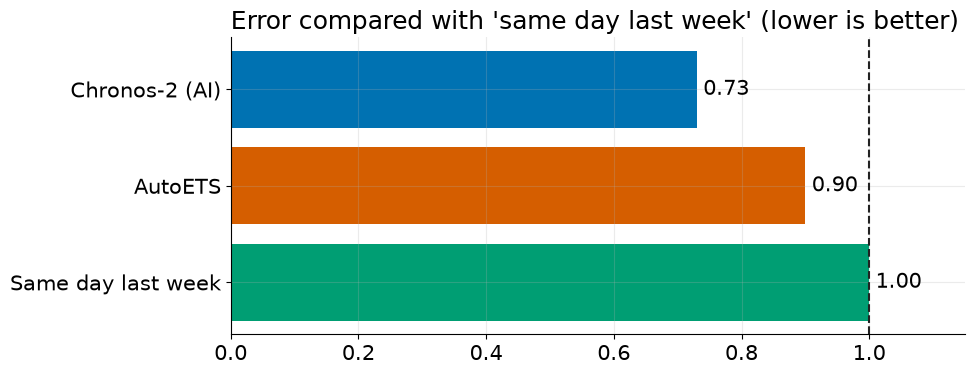

In [9]:
rel = table["relative error"].sort_values(ascending=False)
key = {v: k for k, v in NAMES.items()}
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(rel.index, rel.values, color=[COLORS[key[n]] for n in rel.index])
ax.axvline(1, color="#222", ls="--", lw=1.5)
for i, v in enumerate(rel.values):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=15)
ax.set(title="Error compared with 'same day last week' (lower is better)", xlim=(0, 1.15))
plt.tight_layout(); plt.show()

# Step 7: learn from the mistakes

The average hides the story. **Which days did the best model get most wrong, and why?**

We add two things we know about each day:
- **Rain** in Seattle (Open-Meteo weather data)
- **US public holidays** in our test period

In [10]:
weather = pd.read_csv("data/seattle_weather_daily.csv", parse_dates=["date"]).rename(columns={"date": "ds"})
holidays = {"2026-05-25": "Memorial Day", "2026-06-19": "Juneteenth",
            "2026-07-03": "Independence Day (observed)", "2026-07-04": "Independence Day",
            "2026-09-07": "Labor Day"}

worst = race.assign(miss=race.y - race.Chronos2).merge(weather, on="ds")      # real minus forecast
worst = worst.reindex(worst.miss.abs().sort_values(ascending=False).index).head(8)
worst["day"] = worst.ds.dt.strftime("%a %d %b")
worst["holiday"] = worst.ds.dt.strftime("%Y-%m-%d").map(holidays).fillna("")
worst[["day", "y", "Chronos2", "miss", "rain_mm", "holiday"]].round(0).rename(
    columns={"y": "real bikes", "Chronos2": "forecast", "miss": "real minus forecast"}).set_index("day")

,real bikes,forecast,real minus forecast,rain_mm,holiday
day,,,,,
Mon 25 May,1338.0,4308.0,-2970.0,4.0,Memorial Day
Mon 06 Jul,6755.0,4552.0,2203.0,0.0,
Tue 14 Apr,1893.0,4091.0,-2198.0,19.0,
Wed 15 Apr,1814.0,3935.0,-2121.0,13.0,
Mon 08 Jun,2666.0,4775.0,-2109.0,12.0,
Fri 29 May,2612.0,4637.0,-2025.0,6.0,
Fri 25 Sep,2253.0,4121.0,-1868.0,10.0,
Mon 07 Sep,2746.0,4578.0,-1832.0,0.0,Labor Day


# What the mistakes tell us

- **Negative** = fewer bikes than forecast. Most of the worst days are **rainy days**: people leave the bike at home, and the model did not know it would rain
- Others are **public holidays**: no commute, so a Monday behaves like a Sunday
- One miss goes **the other way**: Monday 6 July was much **busier** than forecast, on a dry, warm day after the holiday weekend. Not every miss has a neat explanation
- These are **not random**. They are information the model **did not have**

**The next level:** give the model a **holiday calendar** and the **weather forecast**.
But careful: it must be the weather **forecast**, not the weather that really happened. Using the real weather is **cheating without knowing it**. That is next week's episode.

# Can we trust the ranges?

An **80% range** should catch the real number about **80% of the time** (golden rule 2 from Episode 1).

- Much less than 80%: **overconfident** (range too narrow)
- Much more than 80%: **too cautious** (range too wide to be useful)

In [11]:
for m in MODELS:
    inside = ((race.y >= race[f"{m}-lo-{LEVEL}"]) & (race.y <= race[f"{m}-hi-{LEVEL}"])).mean()
    width = (race[f"{m}-hi-{LEVEL}"] - race[f"{m}-lo-{LEVEL}"]).mean()
    print(f"{NAMES[m]:20s} caught the truth {inside:5.1%} of the time  (range about {width:,.0f} bikes wide)")

Same day last week   caught the truth 69.8% of the time  (range about 2,288 bikes wide)
AutoETS              caught the truth 66.5% of the time  (range about 1,878 bikes wide)
Chronos-2 (AI)       caught the truth 72.5% of the time  (range about 1,771 bikes wide)


# Step 8: forecast the future

The test is done, so we pick the model with the **lowest error** and give it **all** the data, up to 30 September 2026.

Then we ask for the **next 7 days**, with the 80% range. This is the forecast you would hand to your manager.

Best model in the test: Chronos-2 (AI)


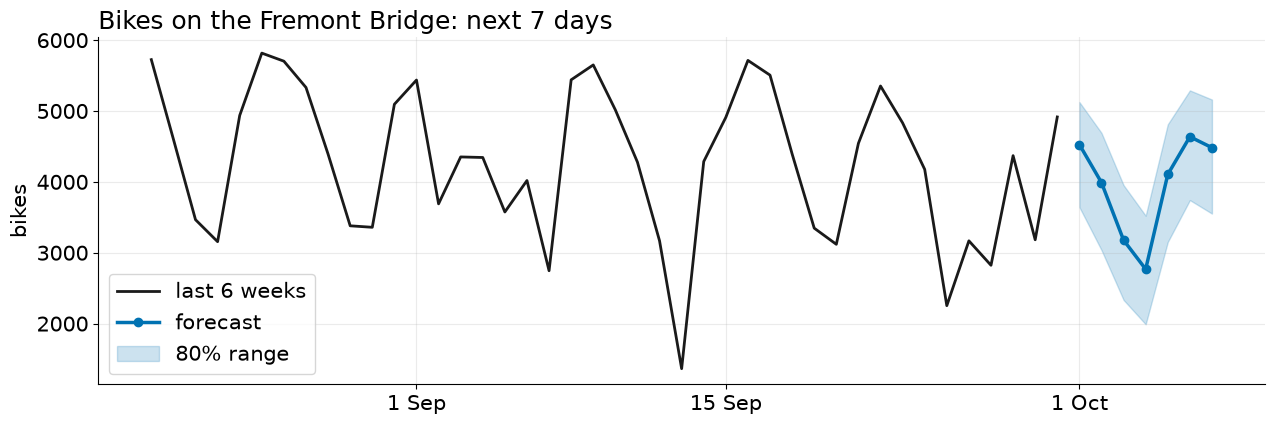

,forecast,low (10%),high (90%)
day,,,
Thu 01 Oct,4530,3640,5130
Fri 02 Oct,3990,3040,4690
Sat 03 Oct,3180,2330,3950
Sun 04 Oct,2770,1990,3520
Mon 05 Oct,4100,3150,4810
Tue 06 Oct,4640,3740,5290
Wed 07 Oct,4480,3550,5160


In [12]:
best = table.index[0]
print("Best model in the test:", best)          # Chronos-2 won, so we use it for the real forecast

future = chronos_forecast(df)
future["day"] = future.ds.dt.strftime("%a %d %b")

fig, ax = plt.subplots(figsize=(13, 4.5))
h = df.tail(42)
ax.plot(h.ds, h.y, color="#1A1A1A", lw=2, label="last 6 weeks")
ax.plot(future.ds, future.Chronos2, color=COLORS["Chronos2"], lw=2.5, marker="o", label="forecast")
ax.fill_between(future.ds, future[f"Chronos2-lo-{LEVEL}"], future[f"Chronos2-hi-{LEVEL}"],
                color=COLORS["Chronos2"], alpha=.2, label="80% range")
ax.set(title="Bikes on the Fremont Bridge: next 7 days", ylabel="bikes"); ax.legend(loc="lower left"); short_dates(ax)
plt.tight_layout(); plt.show()

future.set_index("day")[["Chronos2", f"Chronos2-lo-{LEVEL}", f"Chronos2-hi-{LEVEL}"]].round(-1).astype(int).rename(
    columns={"Chronos2": "forecast", f"Chronos2-lo-{LEVEL}": "low (10%)", f"Chronos2-hi-{LEVEL}": "high (90%)"})

# How to use this forecast

- **The middle line** is the best single guess for each day
- **The range** is your planning tool: "most likely about this many, and 8 times in 10 between low and high"
- **The quietest day** in the week is the obvious day for repairs
- **Check it next week** against what really happened. Forecasting is a habit, not a one-off

*Our range was a little overconfident in the test, so treat the edges as a bit too narrow. Episode 6 shows how to fix that.*

# Your 8-step checklist

1. **Ask a clear question:** what, how far ahead, how often, for which decision
2. **Load** the data in `unique_id`, `ds`, `y` format
3. **Look** at it: trend, rhythms, anything strange
4. **Clean** it: missing days, broken readings
5. **Start with a baseline:** "same day last week"
6. **Test fairly:** backtest on many weeks, using only the past
7. **Learn from the mistakes:** your worst days tell you what the model is missing
8. **Forecast the future, with a range**

The code from today is linked in the description. Swap in your own data and follow the same steps.

# Next episode

## The Forecasting Mistake That Fakes Good Results

How a model that **looks** brilliant in testing can be useless in real life, and three simple checks to catch it. It is called **data leakage**.